# Can we predict the presence of archeological site based on environmental factors ?

**Authors** : 
Dumaine Lucie\
        Lê Trung Toucas Lily

September 2025

## 1. Library import

In [ ]:
# Computing libraries
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
#from sklearn.metrics import confusion_matrix, accuracy_score 

# Graphical libraries
import seaborn as sns
import matplotlib.pyplot as plt

# Modelling libraries
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score, roc_curve


In [ ]:
# Function to plot the coefficients of the regressions

# Code fully generated by GPT-4
def plot_coef(coef) :
    # Sort the coefficients by their absolute values
    sorted_coef = coef.abs().sort_values()

    # Get the original coefficients for coloring
    original_sorted_coef = coef.loc[sorted_coef.index]

    # Create a scatter plot with bars
    plt.figure(figsize=(8, 8))

    # Plot positive coefficients in blue, negative coefficients in red, and near-zero coefficients in grey
    colors = [
        'grey' if abs(coef) < 1e-08 else 'blue' if coef > 0 else 'red'
        for coef in original_sorted_coef
    ]

    plt.scatter(sorted_coef.values, sorted_coef.index, color=colors, zorder = 5)

    # Plot lines from the origin to the dots
    for i in range(len(sorted_coef)):
        plt.plot([0, sorted_coef.values[i]], [i, i], color='skyblue', lw = 2)

    plt.axvline(x=0, color='gray', linestyle='--', linewidth=1)
    plt.xlabel('Absolute Coefficient Value')
    plt.ylabel('Feature')
    plt.title('Regression Coefficients (Absolute Values)')

    plt.show()

## 2. Data import

In [ ]:
df1 = pd.read_csv("Habitat dans le Grand-Est à la période de La Tène - Féliu 2008.csv", sep = ";")

In [ ]:
pd.set_option('display.max_columns', None)
df1.head(5)

,SITE_AKG_ID,SITE_SOURCE_ID,SITE_NAME,MAIN_CITY_NAME,GEONAME_ID,PROJECTION_SYSTEM,LONGITUDE,LATITUDE,ALTITUDE,CITY_CENTROID,STATE_OF_KNOWLEDGE,OCCUPATION,STARTING_PERIOD,ENDING_PERIOD,CARAC_NAME,CARAC_LVL1,CARAC_LVL2,CARAC_LVL3,CARAC_LVL4,CARAC_EXP,ARK_CARAC_ID,AAT_ID,URI_SITE,BIBLIOGRAPHY,COMMENTS
0,1019591,feliu_th_001,"Achenheim, Auf den Ziegelhof",Achenheim,NaN,4326,7.635260,48.582130,NaN,Non,Fouillé,Unique,-75:-26,-75:-26,Immobilier,Habitat,Isolé,Ouvert,NaN,Non,https://ark.frantiq.fr/ark:/26678/pcrt5uHlswsQmN,NaN,https://doi.org/11280/acda1a80,FELIU C. 2008 : Leuques et Médiomatriques à La...,NaN
1,1019592,feliu_th_002,"Agincourt, Graffin",Agincourt,NaN,4326,6.238218,48.723244,NaN,Non,Sondé,Unique,-150:-76,-150:-76,Immobilier,Habitat,Isolé,Enclos,NaN,Non,http://ark.frantiq.fr/ark:/26678/pcrtKei7jxhn32,http://vocab.getty.edu/page/aat/300428748,https://doi.org/11280/acda1a80,FELIU C. 2008 : Leuques et Médiomatriques à La...,NaN
2,1019593,feliu_th_003,"Agincourt, La Presle",Agincourt,NaN,4326,6.224278,48.733730,NaN,Non,Sondé,Unique,-260:-151,-150:-26,Immobilier,Habitat,Isolé,Indéterminé,NaN,Non,NaN,NaN,https://doi.org/11280/acda1a80,FELIU C. 2008 : Leuques et Médiomatriques à La...,NaN
3,1019594,feliu_th_004,"Amnéville, Canton devant l’Église",Amnéville,NaN,4326,6.121558,49.254600,NaN,Non,Fouillé,Unique,-50:-26,-25:449,Immobilier,Habitat,Isolé,Ouvert,NaN,Non,https://ark.frantiq.fr/ark:/26678/pcrt5uHlswsQmN,NaN,https://doi.org/11280/acda1a80,FELIU C. 2008 : Leuques et Médiomatriques à La...,NaN
4,1019595,feliu_th_005,"Apremont-la-Forêt, le Châtelet",Apremont-la-Forêt,NaN,4326,5.638876,48.855343,NaN,Non,Littérature,Unique,-150:-26,-150:-26,Immobilier,Enceinte,Fossé et Talus,NaN,NaN,Non,http://ark.frantiq.fr/ark:/26678/pcrtSaNDeLvKzS,http://vocab.getty.edu/page/aat/300386970,https://doi.org/11280/acda1a80,FELIU C. 2008 : Leuques et Médiomatriques à La...,NaN


In [ ]:
# 1. Chargement des données exportées de SAGA GIS
df2 = pd.read_csv("data_archeo_saga.csv")
df3 = pd.read_csv("pseudo_absences.csv")

# 2. Merge df1 et df2 sur longitude ou sur ID si colonne ID figure dans df2
df = pd.concat(df1, df2, axis='SITE_AKG_ID')
df = df + df3
df.head(5)

## 3. Data cleaning

In [ ]:
# ________ ETAPES _________
# _________________________

# 1. copier le dataframe et Enlever les variables inutiles
# 2. Enlever les lignes pour les colonnes variables à plus de 30% de NaN
# 3. Voir à quels types de site on se limite (habitation, objets, agricole, enceinte, etc) puis on enlève le reste comme monnaie, vaisselle, parure etc je pense
# 4. Ajouter la colonne à prédire "présence" 1 pour les sites si ID 0 si pseudo_absence

In [ ]:
display(df["CARAC_NAME"].value_counts(), df["CARAC_LVL1"].value_counts(), df["CARAC_LVL2"].value_counts(), df["CARAC_LVL3"].value_counts())

CARAC_NAME
Mobilier      801
Immobilier    254
Production    108
Analyses       17
Name: count, dtype: int64

CARAC_LVL1
Métal                      495
Céramique                  302
Habitat                    140
Funéraire                   55
Verre                       47
Agricole                    29
Enceinte                    28
Aménagement hydraulique     24
Autres                      21
Datation                    17
Lithique                    10
Indéterminé                  5
Sel                          4
Circulation                  1
Rituel                       1
Pierre                       1
Name: count, dtype: int64

CARAC_LVL2
Monnaies             237
Vaisselle            218
Parure               135
Isolé                113
Autres                59
Outils                57
Conteneur             40
Forge                 38
Tombe isolée          35
Armement              32
Fossé et Talus        28
Groupé                27
Approvisionnement     24
Urne funéraire        23
Nécropole             20
Grenier               20
Dendrochronologie     12
Silo                   9
Atelier                5
14C                    5
Harnachement           4
Atelier monétaire      2
Édifice religieux      1
Pont                   1
Réduction              1
Extraction             1
Name: count, dtype: int64

CARAC_LVL3
Non renseigné         244
Fibule                 59
Enclos                 59
Indéterminé            57
Amphore                40
Fer                    29
Ouvert                 24
Scories                24
Puits                  24
Textile                19
Parure annulaire       17
Épée                   15
Couteau                14
Autres                 14
Monument funéraire     12
Mouture                10
Ceinture                9
Lance                   8
Enclos funéraire        7
Bronze                  7
Lingots                 7
Toilette                5
Forces                  5
Bouclier                4
Hache                   4
Creuset                 2
Pointe de flèche        2
Briquetage              2
Marteau                 1
Burin                   1
Poids                   1
Char                    1
Microvase               1
Clous                   1
Meule                   1
Name: count, dtype: int64

In [ ]:
# Predicted variable
presence = df['presence'].value_counts()
plt.figure(figsize = (2, 2))
sns.barplot(x = presence.index, y = presence.values)
plt.ylabel('Number of sites')
plt.xlabel('Presence of Sites')

KeyError: 'presence'

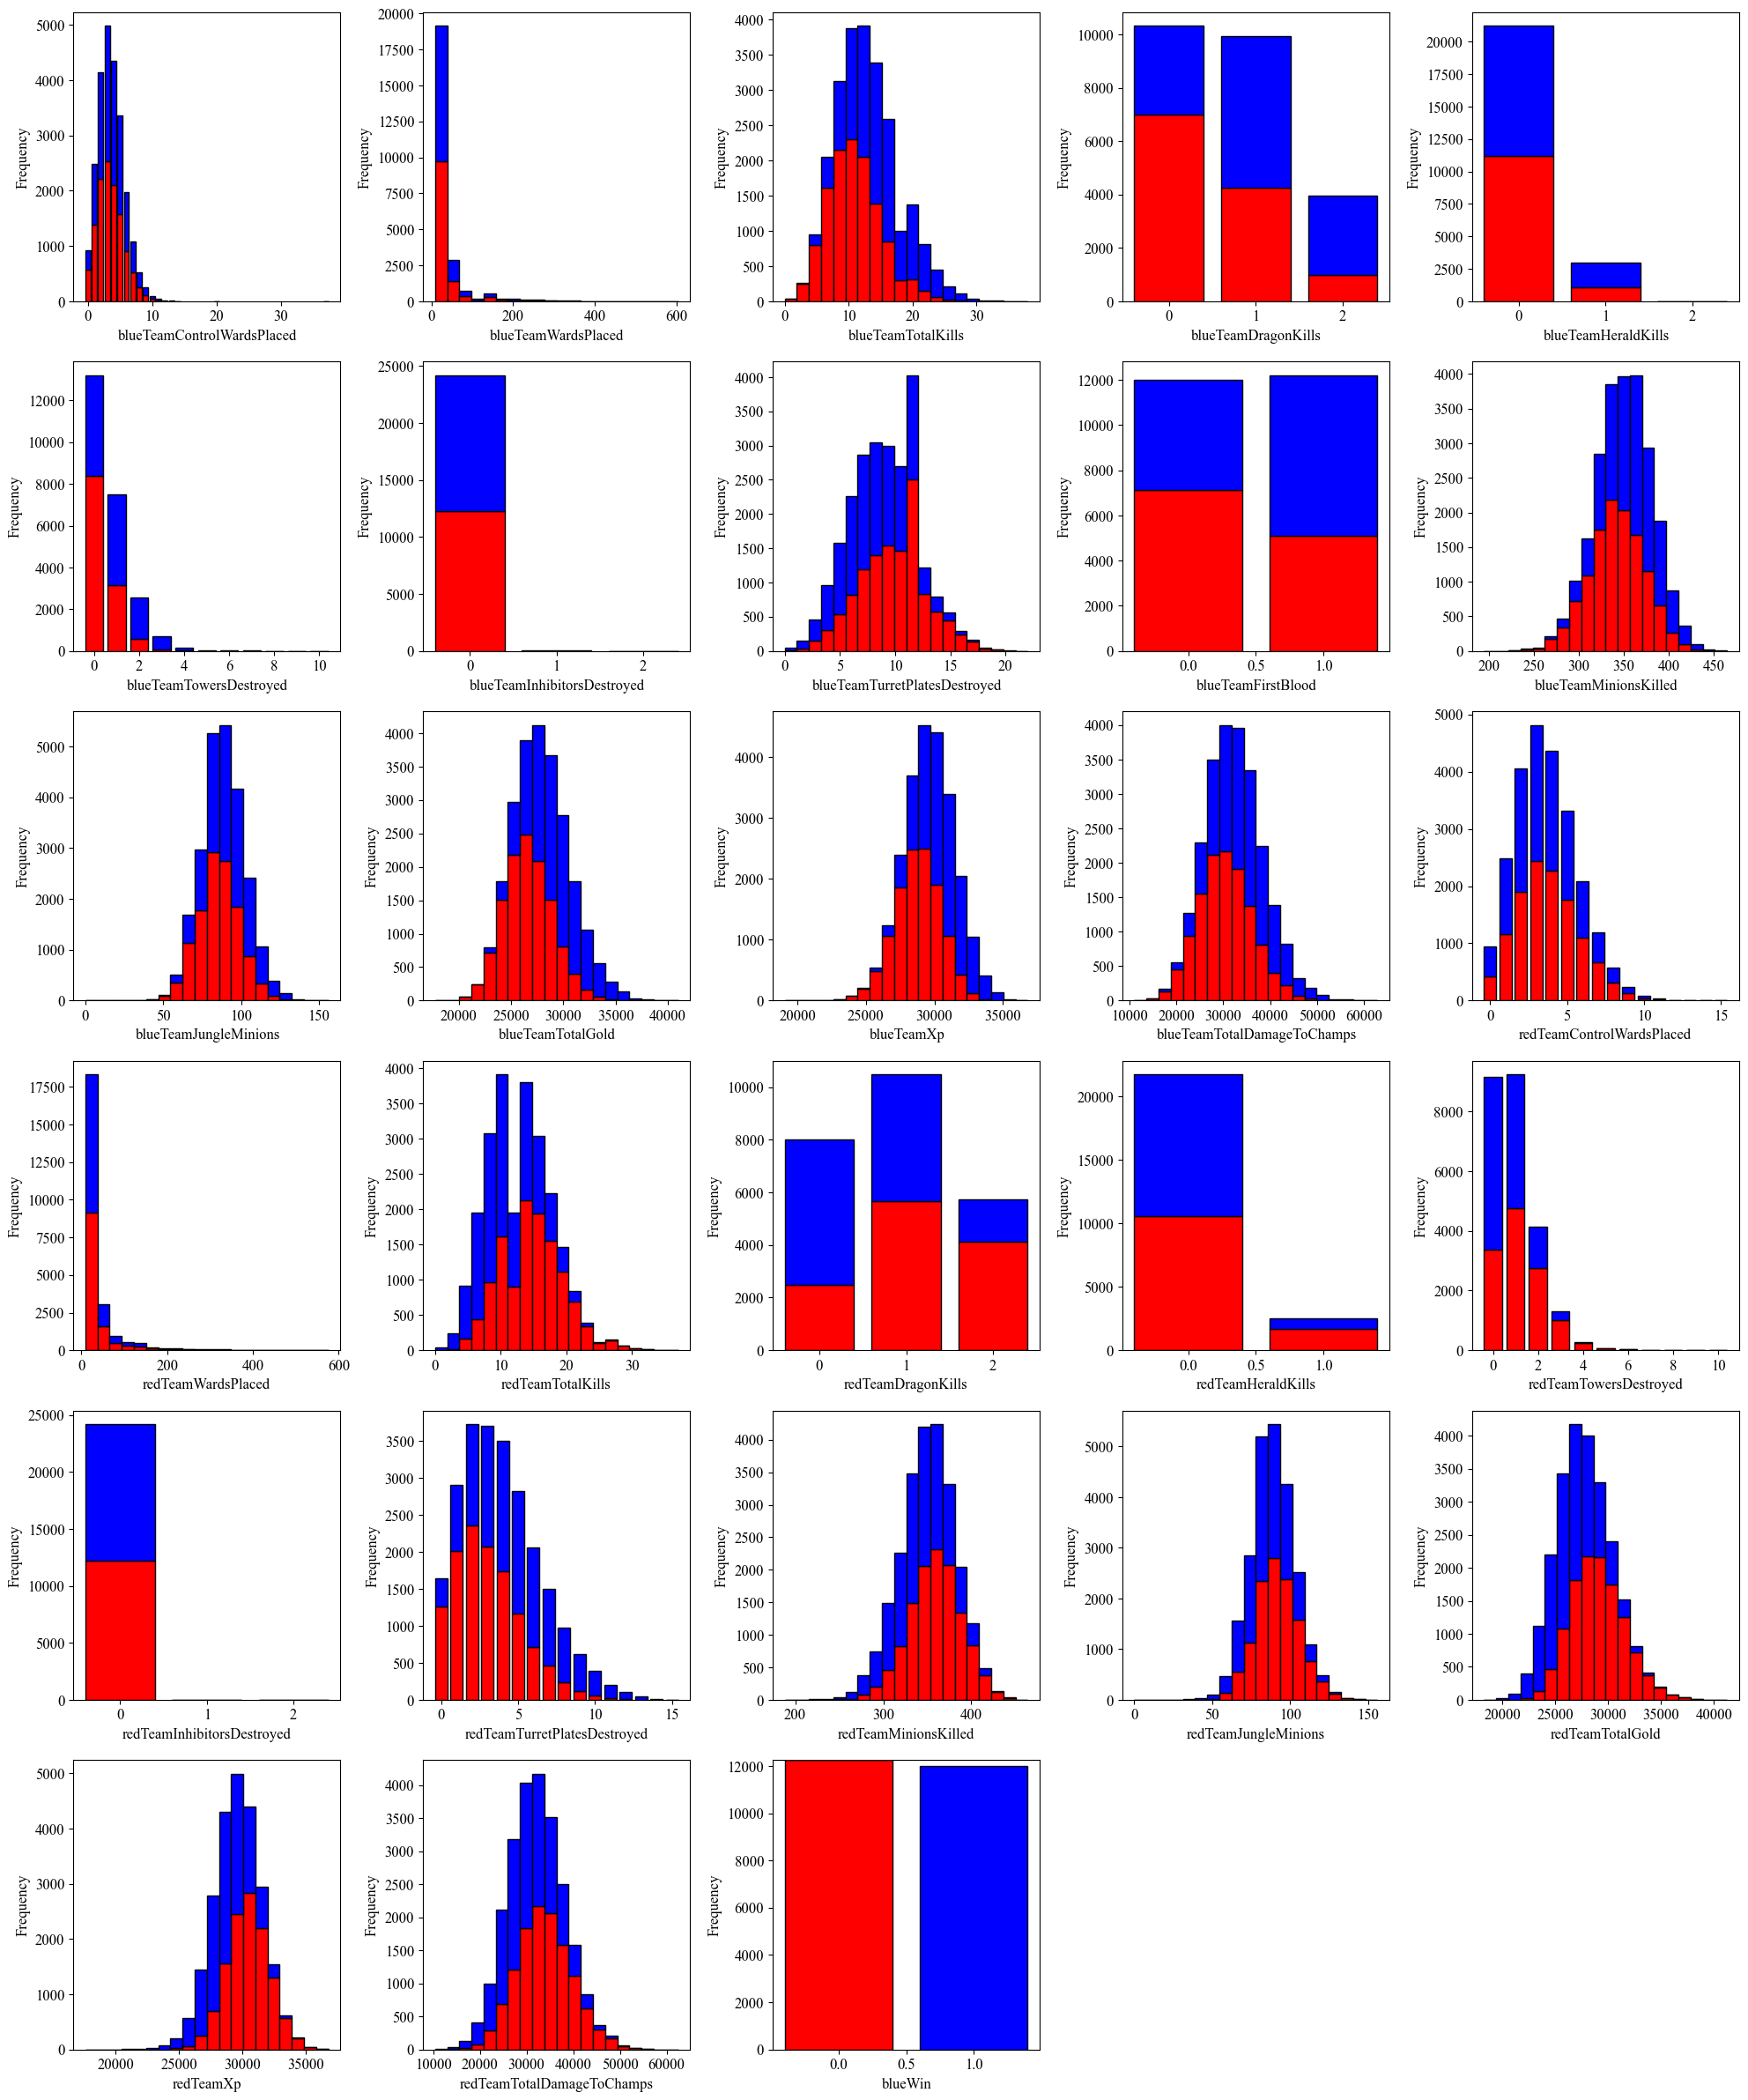

In [ ]:
# Comparison of variables according to archaeological site presence

def plot_variables_by_presence(df, columns):

    n_cols = 2
    n_rows = (len(columns) + 1) // 2

    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(12, 4 * n_rows)
    )

    axes = np.array(axes).reshape(-1)

    for i, col in enumerate(columns):

        axes[i].hist(
            [
                df[df['presence'] == 0][col].dropna(),
                df[df['presence'] == 1][col].dropna()
            ],
            bins=20,
            label=['Absence', 'Presence'],
            alpha=0.7
        )

        axes[i].set_title(col)
        axes[i].set_xlabel(col)
        axes[i].set_ylabel('Frequency')
        axes[i].legend()

    # Hide unused graphs
    for j in range(i + 1, len(axes)):
        axes[j].set_visible(False)

    plt.tight_layout()
    plt.show()


# Environmental variables used in the project
environmental_variables = [
    'altitude',
    'pente',
    'distance_eau',
    'tpi',
    'courbure'
]

plot_variables_by_presence(df, environmental_variables)

## 4. Feature engineering

In [ ]:
# Logarithmic transformations

# No logarithmic transformation is applied at this stage.
# The distributions of the environmental variables are first examined
# to determine whether such a transformation is necessary.

In [ ]:
# Logarithmic transformations

# No logarithmic transformation is applied at this stage.
# The distributions of the environmental variables are first examined
# to determine whether such a transformation is necessary

## 5. Modelling

### 7.1. Logistic regression

#### 7.1.1. Test

In [ ]:
# Explanatory variables
X = df[['altitude', 'pente', 'distance_eau', 'tpi', 'courbure']]

# Target variable
y = df['presence']

# Split into training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Standardization
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Logistic regression
model = LogisticRegression(
    max_iter=5000,
    random_state=42
)

model.fit(X_train_scaled, y_train)

# Predictions
y_pred_train = model.predict(X_train_scaled)
y_pred_test = model.predict(X_test_scaled)

print("Training accuracy:",
      accuracy_score(y_train, y_pred_train))

print("Test accuracy:",
      accuracy_score(y_test, y_pred_test))

#### 7.1.3. Biais / variance diagnostic

The model achieves 76.33% accuracy on the training set, but its accuracy drops slightly to 75.18% on the test set. This small gap suggests limited overfitting (low variance). However, the modest overall accuracy indicates that the model may suffer from bias

### 7.2. Logistic regression with L1 regularization (LASSO)

#### 7.2.1. Train

In [ ]:
# Logistic regression with L1 regularization (LASSO)

lasso_model = LogisticRegression(
    penalty='l1',
    solver='saga',
    max_iter=5000,
    random_state=42
)

lasso_model.fit(X_train_scaled, y_train)

# Predictions
y_pred_train_lasso = lasso_model.predict(X_train_scaled)
y_pred_test_lasso = lasso_model.predict(X_test_scaled)

print(
    "LASSO training accuracy:",
    accuracy_score(y_train, y_pred_train_lasso)
)

print(
    "LASSO test accuracy:",
    accuracy_score(y_test, y_pred_test_lasso)
)

/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


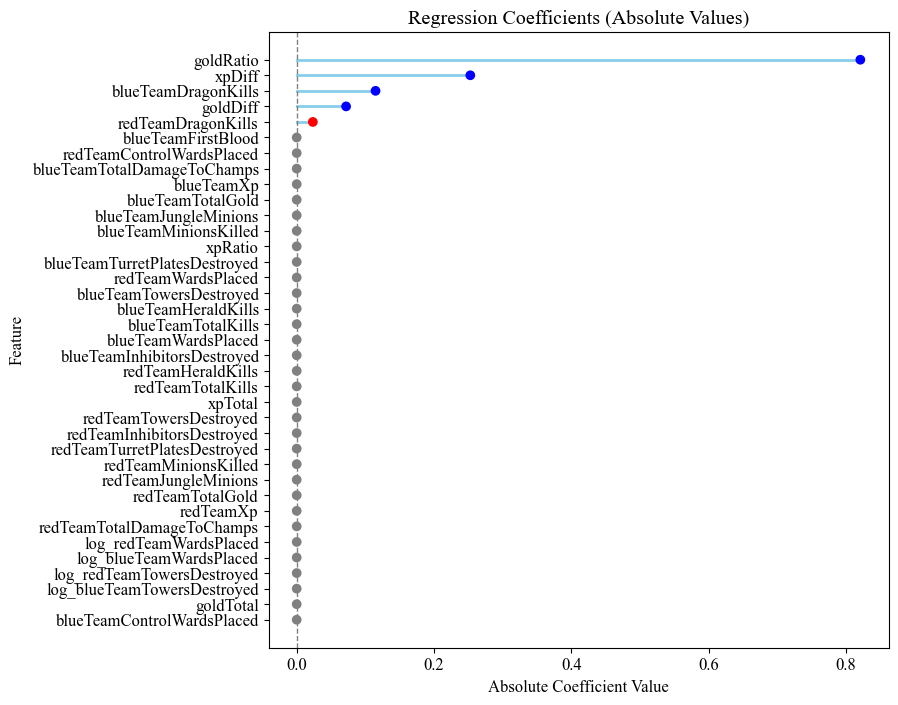

In [ ]:
plot_coef(coef)

In [ ]:
cm = confusion_matrix(y_test, y_pred_test_lasso)

plt.figure(figsize=(5, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Absence', 'Presence'],
    yticklabels=['Absence', 'Presence']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - LASSO')

plt.show()

Confusion Matrix:


,Predicted Win,Predicted Loose
Actual Win,7125,2101
Actual Loose,2263,6679


In [ ]:
print("Accuracy score on train set:")
accuracy_score(y_train, y_pred)

Accuracy score on train set:


0.7597974460590048

#### 7.2.2. Test

In [ ]:
# Test the linear regression
y_pred = reg.predict(X_test)

# Conflusion matrix
cm = confusion_matrix(y_test, y_pred)
cm_df = pd.DataFrame(cm, index = ['Actual Win', 'Actual Loose'], columns = ['Predicted Win', 'Predicted Loose'])

# Display the confusion matrix
print("Confusion Matrix:")
cm_df

Confusion Matrix:


,Predicted Win,Predicted Loose
Actual Win,2299,720
Actual Loose,767,2271


In [ ]:
print("Accuracy score on test set:")
accuracy_score(y_test, y_pred)

Accuracy score on test set:


0.7544989268614826

#### 7.2.3. Biais / variance diagnostic

The model achieves 75.97% accuracy on the training set, but its accuracy drops slightly to 75.45% on the test set. This small gap suggests limited overfitting (low variance). However, the modest overall accuracy indicates that the model may suffer from bias

### 7.3. Logistic regression with L2 regularization (RIDGE)

#### 7.3.1. Train

In [ ]:
# Performing Logistic Regression with L2 regularization
reg = LogisticRegression(penalty = 'l2', solver = 'saga', C = 0.001)
reg.fit(X_train, y_train)

coef = pd.Series(reg.coef_[0], index=X.columns)

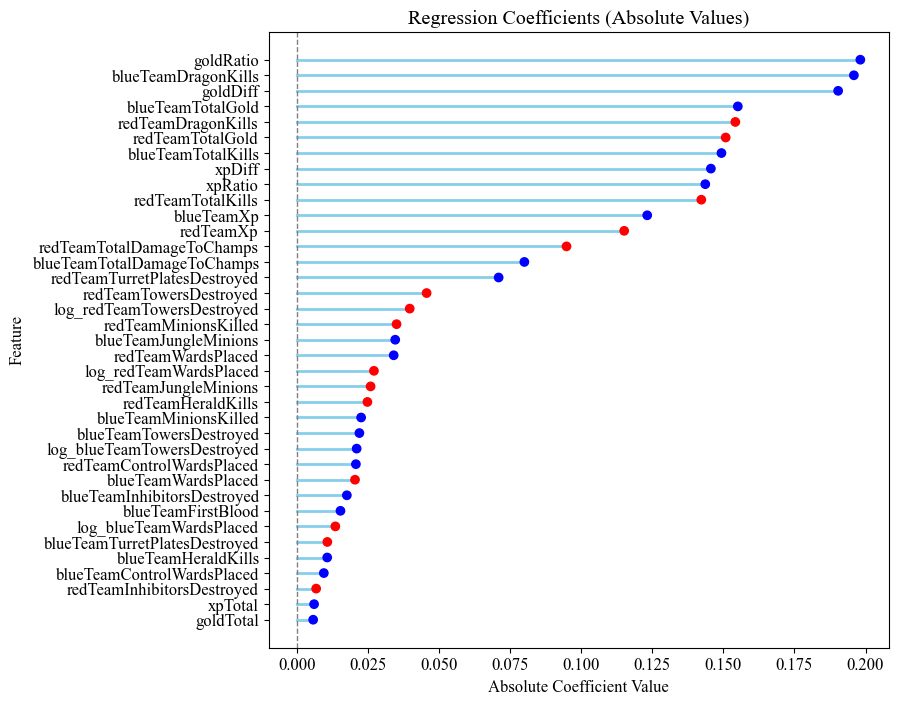

In [ ]:
plot_coef(coef)

In [ ]:
# Train the logistic regression
y_pred = reg.predict(X_train)

# Conflusion matrix
cm = confusion_matrix(y_train, y_pred)
cm_df = pd.DataFrame(cm, index=['Actual Win', 'Actual Loose'], columns = ['Predicted Win', 'Predicted Loose'])
print("Confusion Matrix:")
cm_df

Confusion Matrix:


,Predicted Win,Predicted Loose
Actual Win,7117,2109
Actual Loose,2209,6733


In [ ]:
print("Accuracy score on train set:")
accuracy_score(y_train, y_pred)

Accuracy score on train set:


0.7623293703214443

#### 7.3.2. Test

In [ ]:
# Test the linear regression
y_pred = reg.predict(X_test)

# Conflusion matrix
cm = confusion_matrix(y_test, y_pred)
cm_df = pd.DataFrame(cm, index = ['Actual Win', 'Actual Loose'], columns = ['Predicted Win', 'Predicted Loose'])

# Display the confusion matrix
print("Confusion Matrix:")
cm_df

Confusion Matrix:


,Predicted Win,Predicted Loose
Actual Win,2300,719
Actual Loose,757,2281


In [ ]:
print("Accuracy score on test set:")
accuracy_score(y_test, y_pred)

Accuracy score on test set:


0.7563150074294205

#### 7.3.3. Biais / variance diagnostic

The model achieves 76.23% accuracy on the training set, but its accuracy drops slightly to 75.63% on the test set. This small gap suggests low variance. However, the modest overall accuracy indicates that the model may suffer from bias

## 8. Conclusion

The best model is the Ridge regression model, with an accuracy of 75.63% (better than chance level, at 50%). This means that this model should be able to correctly predict the outcome of a League of Legends game in more than three out of four cases, based on data available 15 minutes after the start of the game.